In [2]:
import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import (NFWPotential, TwoPowerSphericalPotential, AnySphericalPotential,evaluateDensities)
from colossus.cosmology import cosmology
from colossus.halo import concentration, profile_nfw
from scipy.optimize import minimize, fsolve
from math import pi
from galpy.orbit import Orbit       #tri des données euclid
import sys
import pandas as pd
import time
from astropy.constants import G
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, vcirc, FDMDynamicalFrictionForce as FDM_DF
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator
from scipy.signal import argrelextrema

In [3]:
def zeta(z, Omega_m):
    return (18 * np.pi**2 + 82 * (Omega_m - 1) - 39 * (Omega_m - 1)**2) / Omega_m
def r_c(z, M_h, m_22, Omega_m):
    return (1.6 / np.sqrt(1 + z)) * (zeta(z, Omega_m) / zeta(0, Omega_m0))**(-1/6) * (M_h / 1e9)**(-1/3) * m_22**-1
def rho2_z(r_c, m_22, z):
    return 1.9 * (10 * m_22)**-2 * r_c**-4 * 1e9 / ((1 + z)**3)

zgo = 0
cosmo = cosmology.setCosmology('planck18')
Omega_m0 = cosmo.Om(zgo)

def FDMhalo(m22, M):

    Mh=M*0.704
    rc1 = r_c(zgo, M, m22, Omega_m0)
    rhoFDM = rho2_z(rc1, m22, zgo)
    AmpFDM = rhoFDM * 4 * pi * rc1**3

    rc2 = r_c(zgo, M, m22/10, Omega_m0)
    rhoFDM2 = rho2_z(rc2, m22/10, zgo)
    AmpFDM2 = rhoFDM2 * 4 * pi * rc2**3
    
    C2 = concentration.concentration(M*0.704, 'vir', zgo, model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=M*0.704, c=C2, z=zgo, mdef='vir')
    rs = p_nfw.par['rs'] / 0.704
    A=np.log(1+C2)-C2/(1+C2)

    DMhalo2 = NFWPotential(amp=M/A * u.Msun, a=rs*u.kpc)
    r_vals = np.logspace(np.log10(0.001), np.log10(1000), 200)
    FDMhalo_soliton = AnySphericalPotential(dens=lambda r: rhoFDM / ((1 + 0.091 * (r / rc1)**2)**8))

    def cost(params):
        psi, gamma, eta = params
        if psi <= 0 or gamma <= 0 or eta <= 0:
            return np.inf

        def equation(alpha):
            FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
            dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc)
            dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc)
            return (dens_FDM3 - dens_CDM) / dens_CDM

        try:
            alpha_sol = fsolve(equation, 10)[0]
        except:
            return np.inf

        FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha_sol**3) * u.Msun, a=alpha_sol * rc2 * u.kpc, alpha=0, beta=3)
        CoreFDM = TwoPowerSphericalPotential(amp=AmpFDM * (gamma**3) * u.Msun, a=gamma * rc1 * u.kpc, alpha=0, beta=eta)
        total_ref = np.array([evaluateDensities(FDMhalo_soliton, r, 0) + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        total_test = np.array([evaluateDensities(CoreFDM, r * u.kpc, 0 * u.kpc) * 1e9 + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        return np.mean((np.log10(total_ref + 1e-30) - np.log10(total_test + 1e-30))**2)

    result = minimize(cost, x0=[0.5, 12.0, 20.0], bounds=[(0.0001, 0.7 * (1e10 / M) * (10 / m22)), (1, 10), (3, 10)], method='L-BFGS-B')
    psi_opt, gamma_opt, eta_opt = result.x

    def equation(alpha):
        FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
        dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc) * 1e9
        dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc) * 1e9
        return (dens_FDM3 - dens_CDM) / dens_CDM

    alpha_final = fsolve(equation, 10)[0]
    FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha_final**3) * u.Msun, a=alpha_final * rc2 * u.kpc, alpha=0, beta=3)
    CoreFDM = TwoPowerSphericalPotential(amp=(gamma_opt**3) * AmpFDM * u.Msun, a=gamma_opt * rc1 * u.kpc, alpha=0, beta=eta_opt)
    return CoreFDM + FDMhalo3

In [8]:
#Fornax dwarf galaxy, GC3 and GC4 as a function of m22, NFW potential

Ms=2.39e7
rhm=0.01

ts=np.linspace(0,10,501)*u.Gyr
t=ts.value
threshold=0.2
e=0
a=np.sqrt(1+e)
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
RGC=np.array([0.43,0.24])
MGC=np.array([3.63e5,1.32e5])
e=0

Mh = M * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)
os = [[r*u.kpc, 0*u.km/u.s, np.sqrt(1+e)*vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]

m22_values=np.logspace(np.log10(0.1),np.log10(100),25)
#m22_values=np.linspace(0.1,100,30)
"""
all_results_1=[]

for o,mgc in zip(os,MGC):
    gc_results=[]
    for m22 in m22_values:
        orb=Orbit(o)
        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
        gc_results.append({"m22":m22,"r":orb.r(ts)})
    all_results_1.append(gc_results)
"""


#Fornax dwarf galaxy, GC3 and GC4 as a function of m22, FDM potential
all_results_2=[]

for r,mgc in zip(RGC,MGC):
    gc_results=[]
    for m22 in m22_values:
        fdm=FDMhalo(m22,M)
        orb=Orbit([r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(fdm, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg])
        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=fdm,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,fdm+fdf,method='dop853_c')
        gc_results.append({"m22":m22,"r":orb.r(ts)})
    all_results_2.append(gc_results)

orb_classic = []
for i in range(2):
    orb = Orbit(os[i])
    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    orb.integrate(ts, NFW_pot + cdf, method='dop853_c')
    orb_classic.append(orb)

/tmp/ipykernel_1060454/4249495266.py:44: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  alpha_sol = fsolve(equation, 10)[0]

/tmp/ipykernel_1060454/4249495266.py:63: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  alpha_final = fsolve(equation, 10)[0]



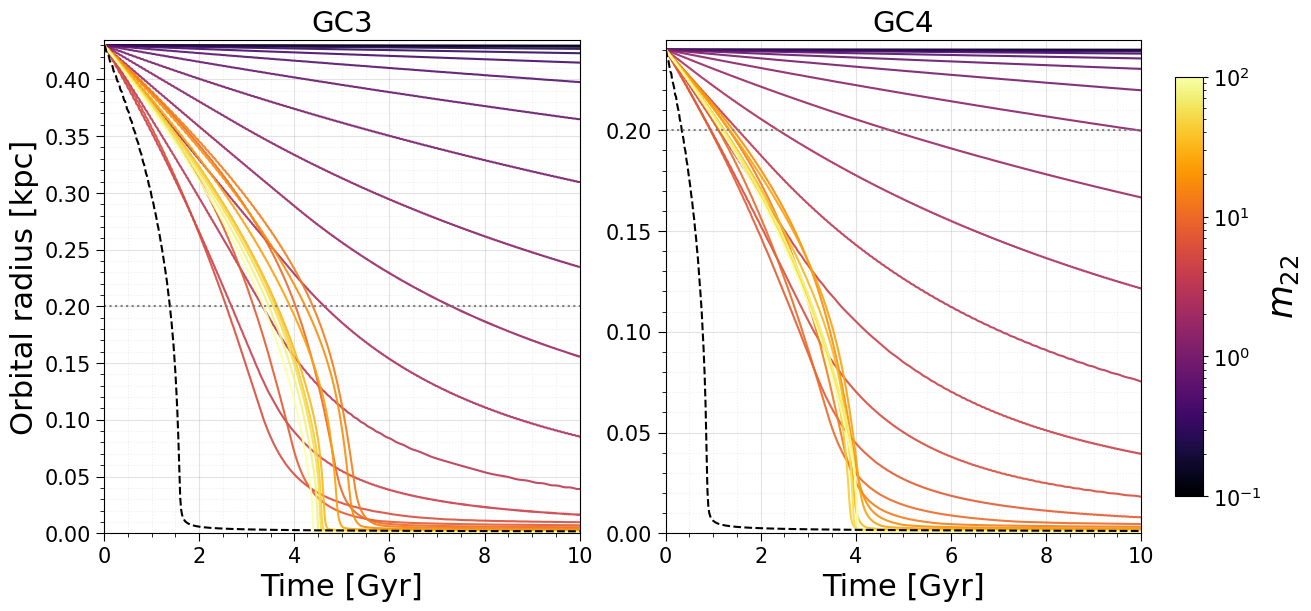

In [17]:
cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())
"""
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, constrained_layout=True)



column_titles = ["NFW potential", "Core potential"]
all_sets = [all_results_1, all_results_2]
ylims = [0.435, 0.245]
for col in range(2):
    for row in range(2):
        ax = axes[row, col]
        for res in all_sets[col][row]:
            ax.plot(t, res["r"], color=cmap(norm(res["m22"])), lw=1.5, alpha=0.9)
        ax.plot(t, orb_classic[row].r(ts), color='black', lw=1.5, ls='--')  
        ax.axhline(0.2, color='grey', linestyle=':', lw=1.5)
        ax.set_xlim(0, 10)
        ax.set_ylim(0, ylims[row])
        ax.minorticks_on()
        ax.grid(True, which='major', linestyle='-', alpha=0.35)
        ax.grid(True, which='minor', linestyle=':', alpha=0.2)
        ax.tick_params(axis='both', which='major', labelsize=12, length=6)
        ax.tick_params(axis='both', which='minor', length=3)
        if row == 0:
            ax.set_title(column_titles[col], fontsize=18)
        if col == 0:
            ax.set_ylabel(f'GC{row+3}\n Orbital radius [kpc]', fontsize=17)
        if row == 1:
            ax.set_xlabel("Time [Gyr]", fontsize=17)

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02, shrink=0.85, aspect=30)
cbar.set_label(r'$m_{22}$', fontsize=17)
cbar.ax.tick_params(labelsize=12)

plt.savefig("comparison_2potentials.png", dpi=300, bbox_inches="tight")
plt.show()
"""





fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, constrained_layout=True)

cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())

results_core = all_results_2

ylims = [0.435, 0.245]

for row in range(2):
    ax = axes[row]
    for res in results_core[row]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])), lw=1.5, alpha=0.9)
    ax.plot(t, orb_classic[row].r(ts), color='black', lw=1.5, ls='--')
    ax.axhline(0.2, color='grey', linestyle=':', lw=1.5)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, ylims[row])
    ax.minorticks_on()
    ax.grid(True, which='major', linestyle='-', alpha=0.35)
    ax.grid(True, which='minor', linestyle=':', alpha=0.2)
    ax.tick_params(axis='both', which='major', labelsize=15, length=6)
    ax.tick_params(axis='both', which='minor', length=3)
    ax.set_title(f"GC{row+3}", fontsize=21)
    ax.set_xlabel("Time [Gyr]", fontsize=22)
axes[0].set_ylabel("Orbital radius [kpc]", fontsize=22)
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02, shrink=0.85, aspect=15)
cbar.set_label(r'$m_{22}$', fontsize=25)
cbar.ax.tick_params(labelsize=15)
plt.savefig("GC3_GC4.png", dpi=300, bbox_inches="tight")
plt.show()

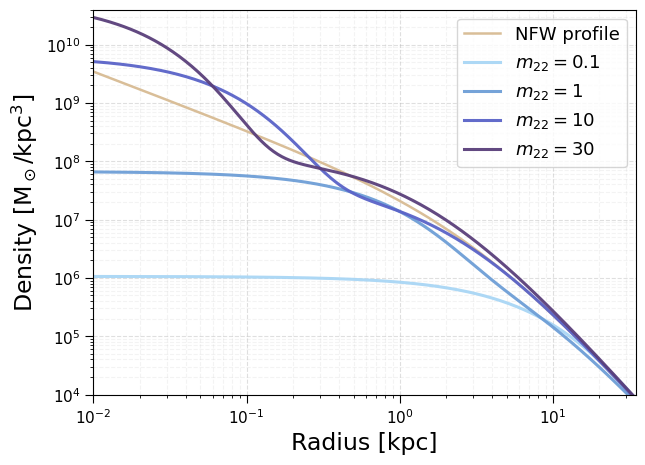

In [27]:
#plot for different core potential

m22 = [0.1, 1, 10,30]  # e-22
M = 1e10
r = np.logspace(-2, 2, 300)
#colors = ["gold","orange", "#D64545", "purple"]
colors = ["#A9D6F5", "#6E9ED6", "#5A63C8", "#5A3F7A"]


C2 = concentration.concentration(M * 0.704, 'vir', zgo, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=M * 0.704, c=C2, z=zgo, mdef='vir')
rs = p_nfw.par['rs'] / 0.704
A = np.log(1 + C2) - C2 / (1 + C2)
DMhalo_NFW = NFWPotential(amp=M / A * u.Msun, a=rs * u.kpc)


plt.figure(figsize=(7,5))

rho_nfw = np.array([evaluateDensities(DMhalo_NFW, ri * u.kpc, 0 * u.kpc) * 1e9 for ri in r])
plt.loglog(r, rho_nfw, color="#D9BE98", lw=1.8, ls="-",label="NFW profile")

for i, m in enumerate(m22):
    pot = FDMhalo(m, M)
    rho = np.array([evaluateDensities(pot, ri * u.kpc, 0 * u.kpc) * 1e9 for ri in r])
    plt.loglog(r, rho, color=colors[i], lw=2.2,alpha=0.95, label=rf"$m_{{22}}={m}$")
plt.tick_params(axis='both', which='major', labelsize=11, length=6)
#ax.tick_params(axis='both', which='minor', length=3)
plt.xlabel("Radius [kpc]", fontsize=17)
plt.ylabel(r"Density $\mathrm{[M_\odot/kpc^3]}$", fontsize=17)
plt.xlim(0.01, 35)
plt.ylim(1e4,4e10)
#plt.grid(True, which="both", ls="--", alpha=0.4)
plt.grid(True, which='major',ls="--", alpha=0.4)
plt.grid(True, which='minor',ls="--", alpha=0.15)
plt.legend(fontsize=13)
plt.savefig("rho_NFW.png", dpi=300, bbox_inches="tight")
plt.show()

2.462777928406157


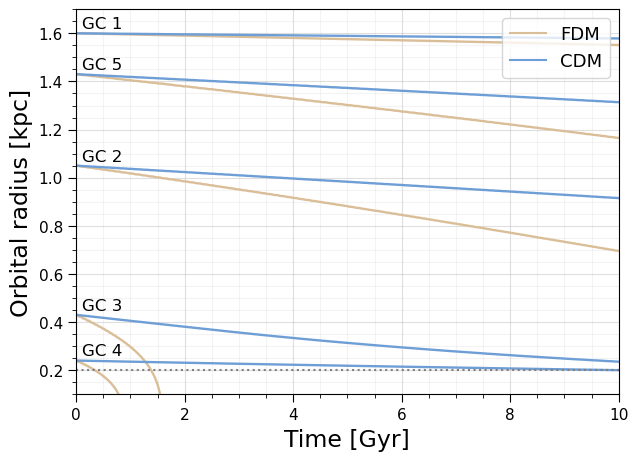

In [6]:
#plot 5 fornax GCs CDM vs FDM

Ms = 2.39e7

halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
print(M*1e-10)

RGC = np.array([1.6, 1.05, 0.43, 0.24, 1.43])          #*(2/np.sqrt(3))
MGC = np.array([0.37e5, 1.82e5, 3.63e5, 1.32e5, 1.78e5])
rhm = 0.01
m = 1.33e-22
mfdm=1.33
Mh = M*0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)
FDM=FDMhalo(mfdm,M)
ocdm = [[r*u.kpc, 0*u.km/u.s, vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]
ofdm = [[r*u.kpc, 0*u.km/u.s, vcirc(FDM, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]

ts = np.linspace(0, 10, 1001) * u.Gyr
t = np.linspace(0, 10, 1001)


def run(i):
    orb_cdf = Orbit(ocdm[i])
    orb_fdf = Orbit(ofdm[i])
    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    fdf = FDM_DF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV)
    orb_cdf.integrate(ts, NFW_pot+cdf, method='dop853_c')
    orb_fdf.integrate(ts, FDM+fdf, method='dop853_c')
    return orb_cdf.r(ts), orb_fdf.r(ts)

res = Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))
rcdf = np.array([r[0] for r in res])
rfdf = np.array([r[1] for r in res])



fig, ax = plt.subplots(figsize=(7,5))
#colors = ['#4C78A8', '#E45756', '#72B7B2', '#F58518', '#54A24B']
colors=["#D9BE98","#6E9ED6"]#D9BE98   #F0DEC2
for i in range(len(RGC)):
    ax.plot(t, rcdf[i], color=colors[0],linestyle='-', lw=1.7)
    ax.plot(t, rfdf[i], color=colors[1], linestyle='-', lw=1.7)
    ax.text(t[0] + 0.1, rcdf[i][0]+0.02, f"GC {i+1}", fontsize=12,color="black")
ax.plot([], [], color=colors[0], linestyle="-", label=rf"FDM")
ax.plot([], [], color=colors[1], linestyle="-", label=rf"CDM")

ax.axhline(0.2, color='grey', linestyle=':', linewidth=1.5)

ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Orbital radius [kpc]", fontsize=17)

ax.minorticks_on()
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_xlim(0, 10)
ax.set_ylim(0.1, 1.7)
ax.legend(frameon=True, fancybox=True, fontsize=13,loc="upper right")
ax.tick_params(axis='both', labelsize=11)
plt.savefig("2.png", dpi=300, bbox_inches="tight")
plt.show()

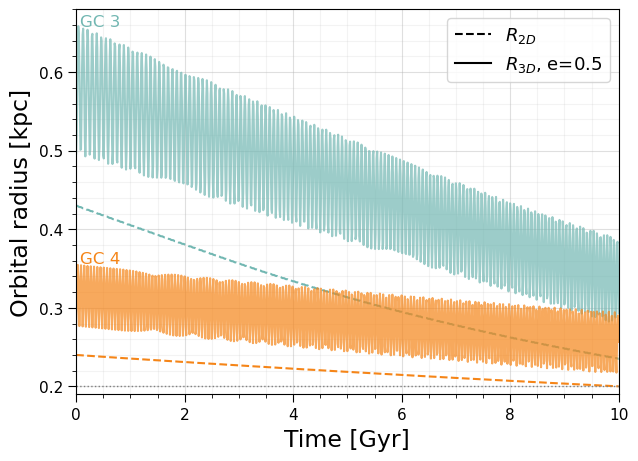

In [26]:
#zoom on GC3,4

y=[0.162,0.08]
Ms = 2.39e7
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
e=0.5
a=np.sqrt(1+e)
p=2/np.sqrt(3)
ts= np.linspace(0.,10,1001)*u.Gyr
GCs=Orbit([[0.43*u.kpc,0.*u.km/u.s,vcirc(FDM,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,vcirc(FDM,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCs3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,vcirc(FDM,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,vcirc(FDM,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s)

GCse=Orbit([[0.43*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCse3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,a*vcirc(FDM,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 

fdm_df= [FDM_DF(GMs=3.63e5*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV),
         FDM_DF(GMs=1.32e5*u.Msun, rhm=rhm*u.kpc, dens=FDM, m=m*u.eV),]
         
cdfs=[CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),      ]  
colors = ['#72B7B2', '#F58518']

fig, ax = plt.subplots(figsize=(7,5))
for i, (o1,o2,o3,o4,df) in enumerate(zip(GCs,GCs3,GCse,GCse3,fdm_df)):
    col = colors[i % len(colors)]
    o1.integrate(ts, FDM + df, method='dop853_c')
    o1.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True, label="_nolegend_")
    #o2.integrate(ts, FDM + df, method='dop853_c')
    #o2.plot(color=col, linestyle=':', d1='t', d2='r', overplot=True, label="_nolegend_")
    #plt.plot(ts.value,o2.r(ts), color="purple")
    #o3.integrate(ts, FDM + df, method='dop853_c')
    #o3.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True, label="_nolegend_")
    o4.integrate(ts, FDM + df, method='dop853_c')
    o4.plot(color=col, linestyle='-', d1='t', d2='r',alpha=0.7, overplot=True, label="_nolegend_")
    ax.text(ts[0].value+0.08, o4.R(ts)[0]+y[i], "GC "+str(i+3), color=col,fontsize=12)

ax.plot([], [], color="black", linestyle="--", label=rf"$R_{{2D}}$")
#ax.plot([], [], color="black", linestyle=":", label=rf"$R_{{3D}}$")
#ax.plot([], [], color="black", linestyle="--", label=rf"$R_{{2D}}$, e=0.5")
ax.plot([], [], color="black", linestyle="-", label=rf"$R_{{3D}}$, e=0.5")
ax.axhline(0.2, color='grey',linewidth=1, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Orbital radius [kpc]", fontsize=17)

ax.minorticks_on()


ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)

ax.set_xlim(0, 10)
ax.set_ylim(0.19, 0.68)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.tick_params(axis='both', labelsize=11)
ax.legend(frameon=True, fancybox=True, shadow=None, fontsize=13)
plt.savefig("GC34.png", dpi=300, bbox_inches="tight")
plt.show()

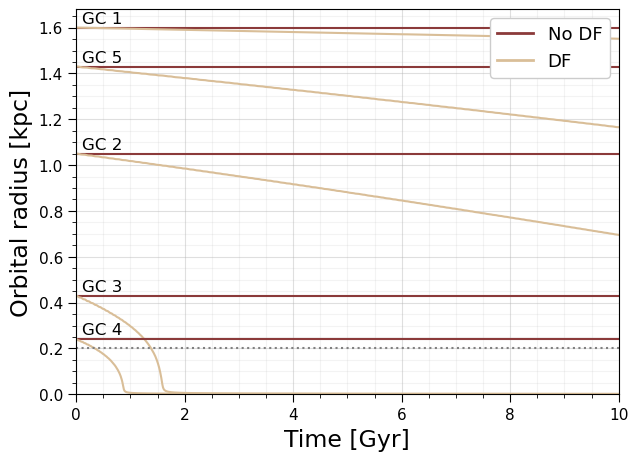

In [33]:
# plot DF vs no DF
Ms = 2.39e7
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
e=0
a=np.sqrt(1+e)
p=2/np.sqrt(3)
ts= np.linspace(0.,10,1001)*u.Gyr


GCs=Orbit([[1.6*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.6*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [1.05*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.05*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [1.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg]]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 


cdfs=[CDFF(GMs=0.37e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.82e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.78e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot)]  

G2=GCs

fig, ax = plt.subplots(figsize=(7,5))

for i, (orbitDF, cd, o2) in enumerate(zip(GCs, cdfs, G2)):
    o2.integrate(ts, NFW_pot, method='dop853_c')
    orbitDF.integrate(ts, NFW_pot + cd, method='dop853_c')
    o2.plot(color='#8B3A3A', linestyle='-', d1='t', d2='r',overplot=True, label="_nolegend_")
    orbitDF.plot(color='#D9BE98', linestyle='-', d1='t', d2='r', overplot=True, label="_nolegend_")

    ax.text(ts[0].value + 0.1, o2.R(ts)[0] + 0.02,f"GC {i+1}", color='black',fontsize=12)

ax.plot([], [], color='#8B3A3A', linestyle='-', linewidth=2, label='No DF')
ax.plot([], [], color='#D9BE98', linestyle='-', linewidth=2, label='DF')
ax.axhline(0.2, color='grey', linewidth=1.5, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Orbital radius [kpc]", fontsize=17)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.68)
ax.minorticks_on()
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=True, loc="upper right", fontsize=13, framealpha=1)
plt.savefig("1.png", dpi=300, bbox_inches="tight")
plt.show()

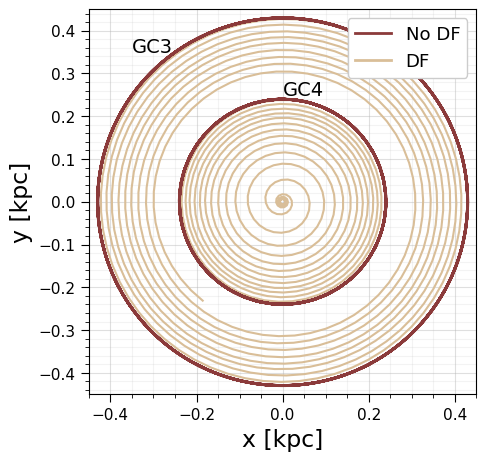

In [80]:
# plot DF vs no DF
Ms = 2.39e7
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
e=0
a=np.sqrt(1+e)
p=2/np.sqrt(3)
ts= np.linspace(0.,1,501)*u.Gyr


GCs=Orbit([[0.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 


cdfs=[CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot)]  

G2=GCs

fig, ax = plt.subplots(figsize=(5,5))

for i, (orbitDF, cd, o2) in enumerate(zip(GCs, cdfs, G2)):
    o2.integrate(ts, NFW_pot, method='dop853_c')
    orbitDF.integrate(ts, NFW_pot + cd, method='dop853_c')
    orbitDF.plot(color='#D9BE98', linestyle='-', d1='x', d2='y', overplot=True, label="_nolegend_")
    o2.plot(color='#8B3A3A', linestyle='-', d1='x', d2='y',linewidth=2,overplot=True, label="_nolegend_")
    

ax.text(-0.35,0.35 , "GC3", color='black', fontsize=14)
ax.text(0, 0.25, "GC4", color='black', fontsize=14)

ax.plot([], [], color='#8B3A3A', linestyle='-', linewidth=2, label='No DF')
ax.plot([], [], color='#D9BE98', linestyle='-', linewidth=2, label='DF')
ax.set_xlabel("x [kpc]", fontsize=17)
ax.set_ylabel("y [kpc]", fontsize=17)
ax.set_xlim(-0.45, 0.45)
ax.set_ylim(-0.45, 0.45)
ax.minorticks_on()
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=True, loc="upper right", fontsize=13, framealpha=1)
plt.savefig("1.png", dpi=300, bbox_inches="tight")
plt.show()